## Step 5A: Check Colab Environment (Python, Java, PySpark)

In [1]:
import importlib
import os
import shutil
import subprocess
import sys

print("Colab Environment Check")
print("-" * 40)
print(f"Python version : {sys.version.split()[0]}")
print(f"CPU cores      : {os.cpu_count()}")

try:
    import psutil
    print(f"RAM (GB)       : {psutil.virtual_memory().total / 1e9:.1f}")
except ImportError:
    print("RAM (GB)       : n/a")

print()
print(f"{'Package':<10}{'Status':<10}Version")
for name in ["numpy", "pandas", "pyarrow", "pyspark"]:
    try:
        module = importlib.import_module(name)
        print(f"{name:<10}{'OK':<10}{getattr(module, '__version__', 'n/a')}")
    except ImportError:
        print(f"{name:<10}{'MISSING':<10}-")

print()
if shutil.which("java"):
    result = subprocess.run(["java", "-version"], capture_output=True, text=True)
    print(f"Java           : found ({result.stderr.splitlines()[0]})")
else:
    print("Java           : NOT FOUND")

Colab Environment Check
----------------------------------------
Python version : 3.13.18
CPU cores      : 2
RAM (GB)       : 13.6

Package   Status    Version
numpy     OK        2.4.6
pandas    OK        2.2.3
pyarrow   OK        23.0.1
pyspark   OK        4.0.5

Java           : found (openjdk version "21.0.12.1" 2026-08-18)


## Step 5B: Upload the Data Generator to Colab

In [2]:
from google.colab import files

# A file picker will open: choose src/data_generator.py from your laptop
uploaded = files.upload()
print("Uploaded:", list(uploaded))

Saving data_generator.py to data_generator.py
Uploaded: ['data_generator.py']


## Step 5C: Generate 100k, 1M and 10M Records as Parquet

In [3]:
import os
import sys
import time

import pyarrow as pa
import pyarrow.parquet as pq

sys.path.append("/content")
from data_generator import generate_ad_data, SEED

DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)


def generate_to_parquet(n_rows, path, chunk_rows=1_000_000, seed=SEED):
    """Generate data in chunks and append each chunk to one Parquet file."""
    writer = None
    done, chunk_no = 0, 0
    while done < n_rows:
        rows = min(chunk_rows, n_rows - done)
        chunk = generate_ad_data(rows, seed=seed + chunk_no)
        table = pa.Table.from_pandas(chunk, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(path, table.schema)
        writer.write_table(table)
        done += rows
        chunk_no += 1
    writer.close()


sizes = {"100k": 100_000, "1M": 1_000_000, "10M": 10_000_000}

print(f"{'Dataset':<10}{'Rows':>12}{'Size (MB)':>12}{'Time (s)':>10}  Rows check")
for label, n_rows in sizes.items():
    path = f"{DATA_DIR}/ads_{label}.parquet"
    if os.path.exists(path):
        print(f"{label:<10}  already exists, not overwritten")
        continue
    start = time.perf_counter()
    generate_to_parquet(n_rows, path)
    seconds = time.perf_counter() - start
    size_mb = os.path.getsize(path) / 1e6
    verified = pq.ParquetFile(path).metadata.num_rows == n_rows
    print(f"{label:<10}{n_rows:>12,}{size_mb:>12.1f}{seconds:>10.1f}  {'PASS' if verified else 'FAIL'}")

Dataset           Rows   Size (MB)  Time (s)  Rows check
100k           100,000         2.4       0.4  PASS
1M           1,000,000        19.8       3.0  PASS
10M         10,000,000       198.3      32.4  PASS


## Step 5D: Regenerate Parquet Files with Spark-Compatible Dates

In [5]:
import glob
import os
import sys
import time

import pyarrow as pa
import pyarrow.parquet as pq

sys.path.append("/content")
from data_generator import generate_ad_data, SEED

DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

# Remove the old Parquet copies (they are rebuilt below with the same seed)
for old_file in glob.glob(f"{DATA_DIR}/ads_*.parquet"):
    os.remove(old_file)


def generate_to_parquet(n_rows, path, chunk_rows=1_000_000, seed=SEED):
    """Generate data in chunks and append each chunk to one Parquet file."""
    writer = None
    done, chunk_no = 0, 0
    while done < n_rows:
        rows = min(chunk_rows, n_rows - done)
        chunk = generate_ad_data(rows, seed=seed + chunk_no)
        table = pa.Table.from_pandas(chunk, preserve_index=False)

        # Store the date as a plain date (no time part) so Spark can read it
        date_index = table.schema.get_field_index("date")
        table = table.set_column(date_index, "date", table["date"].cast(pa.date32()))

        if writer is None:
            writer = pq.ParquetWriter(path, table.schema)
        writer.write_table(table)
        done += rows
        chunk_no += 1
    writer.close()


sizes = {"10k": 10_000, "100k": 100_000, "1M": 1_000_000, "10M": 10_000_000}

print(f"{'Dataset':<10}{'Rows':>12}{'Size (MB)':>12}{'Time (s)':>10}  {'Rows check':<12}Date type")
for label, n_rows in sizes.items():
    path = f"{DATA_DIR}/ads_{label}.parquet"
    start = time.perf_counter()
    generate_to_parquet(n_rows, path)
    seconds = time.perf_counter() - start
    size_mb = os.path.getsize(path) / 1e6
    parquet_file = pq.ParquetFile(path)
    verified = parquet_file.metadata.num_rows == n_rows
    date_type = parquet_file.schema_arrow.field("date").type
    print(f"{label:<10}{n_rows:>12,}{size_mb:>12.1f}{seconds:>10.1f}  "
          f"{'PASS' if verified else 'FAIL':<12}{date_type}")

Dataset           Rows   Size (MB)  Time (s)  Rows check  Date type
10k             10,000         0.3       0.0  PASS        date32[day]
100k           100,000         2.4       0.4  PASS        date32[day]
1M           1,000,000        19.8       3.0  PASS        date32[day]
10M         10,000,000       198.3      31.2  PASS        date32[day]


## Step 6A: Define Pandas, MapReduce and Spark Methods and Test on 100k Records

In [6]:
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

DATA_DIR = "/content/data"
KEY = "platform"
VALUE_COLUMNS = ["impressions", "clicks", "spend", "conversions", "revenue"]
READ_COLUMNS = [KEY] + VALUE_COLUMNS


# ---------- Method 1: Pandas ----------
def run_pandas(path):
    """Load the needed columns fully into memory, then group and sum."""
    df = pd.read_parquet(path, columns=READ_COLUMNS)
    return df.groupby(KEY)[VALUE_COLUMNS].sum().astype(float).sort_index()


# ---------- Method 2: MapReduce style ----------
def map_record(record):
    """Map step: turn one row into a (key, values) pair."""
    return record[0], record[1:]


def reduce_pair(totals, key, values):
    """Reduce step: add one pair's values to the running total of its key."""
    total = totals.setdefault(key, [0, 0, 0.0, 0, 0.0])
    total[0] += values[0]
    total[1] += values[1]
    total[2] += values[2]
    total[3] += values[3]
    total[4] += values[4]


def run_mapreduce(path, batch_rows=1_000_000):
    """Read the file in batches, map every row, then reduce by key."""
    totals = {}
    for batch in pq.ParquetFile(path).iter_batches(batch_size=batch_rows,
                                                   columns=READ_COLUMNS):
        columns = [batch.column(name).to_pylist() for name in READ_COLUMNS]
        for record in zip(*columns):
            key, values = map_record(record)
            reduce_pair(totals, key, values)
    result = pd.DataFrame.from_dict(totals, orient="index", columns=VALUE_COLUMNS)
    return result.astype(float).sort_index()


# ---------- Method 3: Spark ----------
spark = (SparkSession.builder
         .master("local[*]")
         .appName("ad_budget_benchmark")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")


def run_spark(path):
    """Read with Spark, aggregate in parallel, and bring the small result back."""
    rows = (spark.read.parquet(path)
            .groupBy(KEY)
            .agg(*[F.sum(c).alias(c) for c in VALUE_COLUMNS])
            .collect())
    result = pd.DataFrame([row.asDict() for row in rows]).set_index(KEY)
    return result[VALUE_COLUMNS].astype(float).sort_index()


def results_match(reference, other):
    """True if two result tables contain the same totals."""
    other = other.reindex(reference.index)[reference.columns]
    return bool(np.allclose(reference.values, other.values, rtol=1e-9))


# ---------- Test on 100k records ----------
test_path = f"{DATA_DIR}/ads_100k.parquet"
results = {}

print("Single test run on 100,000 records")
for name, method in [("Pandas", run_pandas),
                     ("MapReduce", run_mapreduce),
                     ("Spark", run_spark)]:
    start = time.perf_counter()
    results[name] = method(test_path)
    print(f"  {name:<10}{time.perf_counter() - start:>8.2f} s")

print("\nTotals per platform (Pandas result)")
print(results["Pandas"].to_string(float_format=lambda x: f"{x:,.2f}"))

print("\nResult check against Pandas")
for name in ["MapReduce", "Spark"]:
    status = "PASS" if results_match(results["Pandas"], results[name]) else "FAIL"
    print(f"  {name:<10}{status}")

Single test run on 100,000 records
  Pandas        0.06 s
  MapReduce     0.45 s
  Spark         5.06 s

Totals per platform (Pandas result)
             impressions        clicks          spend  conversions          revenue
platform                                                                           
Facebook  594,934,587.00  6,364,895.00 209,446,368.99   171,936.00   782,152,796.92
Google    479,504,835.00 15,288,879.00 723,499,884.22   571,331.00 3,188,802,659.09
Instagram 598,580,292.00  5,763,082.00 270,639,307.13   216,389.00 1,096,055,676.59
TikTok    360,490,824.00  6,165,772.00  90,679,778.28    79,858.00   243,153,262.14
YouTube   361,921,617.00  1,934,486.00 108,919,559.35    41,448.00   189,265,198.23

Result check against Pandas
  MapReduce PASS
  Spark     PASS


## Step 6B: Benchmark Pandas vs MapReduce vs Spark (10k to 10M Records)

In [7]:
import statistics
import time

import pandas as pd

REPEATS = 3
sizes = {"10k": 10_000, "100k": 100_000, "1M": 1_000_000, "10M": 10_000_000}
methods = {"Pandas": run_pandas, "MapReduce": run_mapreduce, "Spark": run_spark}

# Warm-up run on the smallest file (not timed)
for method in methods.values():
    method(f"{DATA_DIR}/ads_10k.parquet")

records = []
for label, n_rows in sizes.items():
    path = f"{DATA_DIR}/ads_{label}.parquet"
    row = {"Dataset": label, "Rows": n_rows}
    reference = None
    all_match = True

    for name, method in methods.items():
        run_times = []
        for _ in range(REPEATS):
            start = time.perf_counter()
            result = method(path)
            run_times.append(time.perf_counter() - start)
        row[f"{name} (s)"] = statistics.median(run_times)

        # Compare every tool's totals with the first tool (Pandas)
        if reference is None:
            reference = result
        else:
            all_match = all_match and results_match(reference, result)

    row["Results match"] = "PASS" if all_match else "FAIL"
    records.append(row)
    print(f"Finished {label}")

# Build the final table
benchmark = pd.DataFrame(records)
time_columns = ["Pandas (s)", "MapReduce (s)", "Spark (s)"]
benchmark["Fastest"] = benchmark[time_columns].idxmin(axis=1).str.replace(" (s)", "", regex=False)

display_table = benchmark.copy()
display_table["Rows"] = display_table["Rows"].map("{:,}".format)

print("\nBenchmark results (median of 3 runs, Colab with 2 CPU cores)\n")
print(display_table.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

benchmark.to_csv("/content/benchmark_results.csv", index=False)
print("\nSaved: /content/benchmark_results.csv")

Finished 10k
Finished 100k
Finished 1M
Finished 10M

Benchmark results (median of 3 runs, Colab with 2 CPU cores)

Dataset       Rows  Pandas (s)  MapReduce (s)  Spark (s) Results match Fastest
    10k     10,000        0.01           0.07       0.57          PASS  Pandas
   100k    100,000        0.06           0.41       0.57          PASS  Pandas
     1M  1,000,000        0.24           4.60       1.57          PASS  Pandas
    10M 10,000,000        2.39          48.01       4.40          PASS  Pandas

Saved: /content/benchmark_results.csv


## Step 6C: Plot Benchmark Results and Download Files

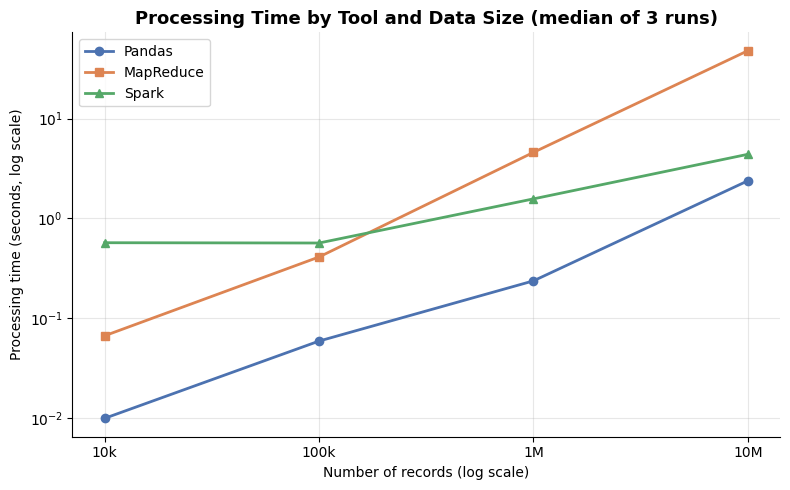

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

benchmark = pd.read_csv("/content/benchmark_results.csv")

styles = {
    "Pandas (s)": ("Pandas", "#4C72B0", "o"),
    "MapReduce (s)": ("MapReduce", "#DD8452", "s"),
    "Spark (s)": ("Spark", "#55A868", "^"),
}

fig, ax = plt.subplots(figsize=(8, 5))
for column, (label, color, marker) in styles.items():
    ax.plot(benchmark["Rows"], benchmark[column],
            marker=marker, color=color, label=label, linewidth=2)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(benchmark["Rows"])
ax.set_xticklabels(["10k", "100k", "1M", "10M"])
ax.minorticks_off()
ax.set_title("Processing Time by Tool and Data Size (median of 3 runs)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Number of records (log scale)")
ax.set_ylabel("Processing time (seconds, log scale)")
ax.grid(True, alpha=0.3)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("/content/05_benchmark_comparison.png", dpi=200)
plt.show()

# Download the chart and the results table to the laptop
files.download("/content/05_benchmark_comparison.png")
files.download("/content/benchmark_results.csv")